# 04. Регрессионный анализ прогнозных оценок


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт объясняет индексы через измерения, оценки и категории: простые регрессии и поиск взаимодействий.

| | |
|---|---|
| **Данные** | `data/scores_norm.csv`, `data/metric_averages.csv` |
| **Методы** | линейная регрессия, центрирование, `glinternet` |
| **Индексы** | сводный, процессный, продуктовый |


In [2]:
library(tidyr)
library(dplyr)
library(glinternet)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Loaded glinternet 1.0.12



In [3]:
indexes <- c("overall_index", "process_index", "product_index")
estimates <- c("output", "related", "frequency", "yield", "volume", "defect")
pipes <- c("output_pipe", "related_pipe", "frequency_pipe", "yield_pipe", "volume_pipe", "defect_pipe")
cat_columns <- c("type", "year", "series", "class", "plant", "mark", "method", "certified")
references <- c("A", "2024", "Серия_1", "Неизвестно", "Площадка_1", "Неизвестно", "Стандартный", "Нет")
estimated_columns <- c(estimates, indexes)


# 1. Введение

Регрессия показывает характер и силу зависимости между индексом и набором объясняющих переменных. Цель — модели, которые объясняют вариацию индекса изменениями оценок, измерений и категорий.

# 2. Данные

1. Берём нормированные оценки и индексы.  
2. Убираем пропуски в оценках и индексах.  
3. Пропуски в категориях заменяем на «Неизвестно».  
4. Присоединяем средние измеренные показатели по каждому контуру.  
5. Масштабируем часть измерений, чтобы коэффициенты читались в удобных единицах.


In [4]:
scores_norm <- read.csv("data/scores_norm.csv") %>%
  mutate(across(all_of(cat_columns), as.character)) %>%
  mutate(across(all_of(cat_columns), ~ replace_na(., "Неизвестно"))) %>%
  mutate(across(all_of(cat_columns), as.factor)) %>%
  left_join(read.csv("data/metric_averages.csv"), by = "item_id", suffix = c("", "_pipe")) %>%
  mutate(across(all_of(c(estimates, pipes)), as.numeric)) %>%
  mutate(
    output_pipe = output_pipe * 1000,
    related_pipe = related_pipe * 1000,
    yield_pipe = yield_pipe * 100
  )


После подготовки в выборке **`r length(unique(scores_norm$item_id))`** изделий.


In [5]:
linear_model_construction <- function(dataset, var_1, var_2, cen) {
  data <- dataset %>%
    select(item_id, all_of(c(var_1, var_2))) %>%
    drop_na()
  if (var_2 %in% c(estimates, pipes)) {
    data[[var_2]] <- data[[var_2]] - cen
  } else if (var_2 %in% cat_columns) {
    data[[var_2]] <- factor(data[[var_2]], levels = c(cen, setdiff(unique(as.character(data[[var_2]])), cen)))
  }
  model <- lm(data[[var_1]] ~ data[[var_2]])
  model$coef
}

linear_model_one <- function(dataset, vec_1, vec_2, vec_cent) {
  as.data.frame(t(mapply(
    function(x, y, z) linear_model_construction(dataset, x, y, z),
    vec_1, vec_2, vec_cent
  ))) %>%
    `rownames<-`(vec_2) %>%
    rename_with(~ c("intercept", "coefficient")) %>%
    mutate(centered = vec_cent)
}

linear_model_cat <- function(dataset, var_1, var_2, cen) {
  coef <- linear_model_construction(dataset, var_1, var_2, cen)
  as.data.frame(coef) %>%
    rename_with(~ c("coefficients")) %>%
    mutate(features = rownames(.)) %>%
    mutate(features = case_when(
      features != "(Intercept)" ~ substr(features, 14, nchar(features)),
      TRUE ~ paste("Intercept -", cen)
    )) %>%
    `rownames<-`(NULL) %>%
    select(features, coefficients) %>%
    arrange(desc(coefficients))
}

plot_coefs <- function(df, title, y = "coefficient") {
  df %>%
    mutate(feature = rownames(.)) %>%
    ggplot(aes(x = reorder(feature, .data[[y]]), y = .data[[y]], fill = .data[[y]] > 0)) +
    geom_col() +
    coord_flip() +
    scale_fill_manual(values = c("TRUE" = "#2c7bb6", "FALSE" = "#d7191c"), guide = "none") +
    labs(title = title, x = NULL, y = "Коэффициент") +
    theme_minimal(base_size = 13) +
    theme(plot.title = element_text(hjust = 0.5))
}


# 3. Оценки, индексы и измерения

Связь прямая: измерение лежит в основе оценки, индекс собирается из оценок.

- **intercept** — значение оценки/индекса, если показатель равен `centered`.  
- **coefficient** — насколько изменится результат, если показатель вырастет на 1 от `centered`.

## 3.1. Каждая оценка и её измерительный контур

Центрируем измерения: нулевая производительность или нулевой выход годного плохо интерпретируются.




|               | intercept| coefficient| centered|
|:--------------|---------:|-----------:|--------:|
|output_pipe    |    98.871|       0.811|      100|
|related_pipe   |   177.138|       0.782|      200|
|frequency_pipe |     1.011|       0.980|        1|
|yield_pipe     |    90.021|       0.978|       90|
|volume_pipe    |     1.014|       0.988|        1|
|defect_pipe    |    48.128|       0.948|       50|


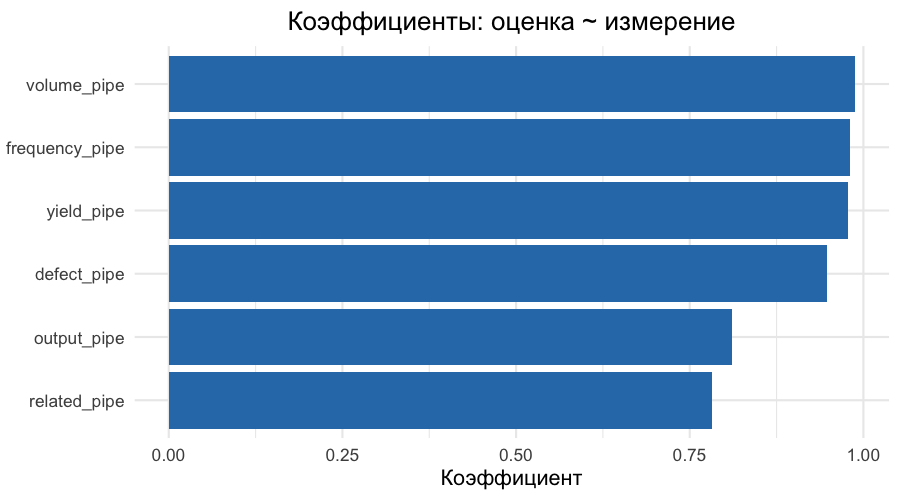

In [6]:
pipe_one <- linear_model_one(scores_norm, estimates, paste0(estimates, "_pipe"), c(100, 200, 1, 90, 1, 50))
knitr::kable(pipe_one, digits = 3)
print(plot_coefs(pipe_one, "Коэффициенты: оценка ~ измерение"))


Связь на графике для производительности и брака:


`geom_smooth()` using formula = 'y ~ x'


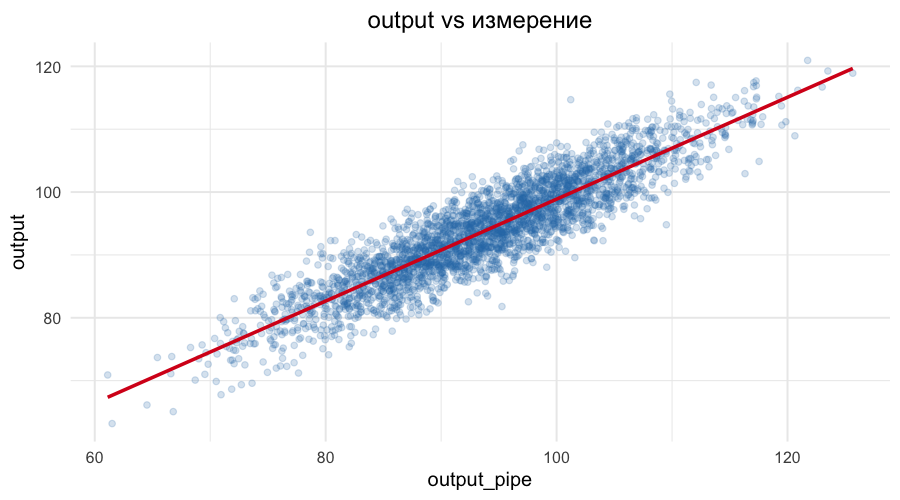

In [7]:
ggplot(scores_norm, aes(output_pipe, output)) +
  geom_point(alpha = 0.2, color = "#2c7bb6") +
  geom_smooth(method = "lm", se = FALSE, color = "#d7191c") +
  labs(title = "output vs измерение", x = "output_pipe", y = "output") +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5))


`geom_smooth()` using formula = 'y ~ x'


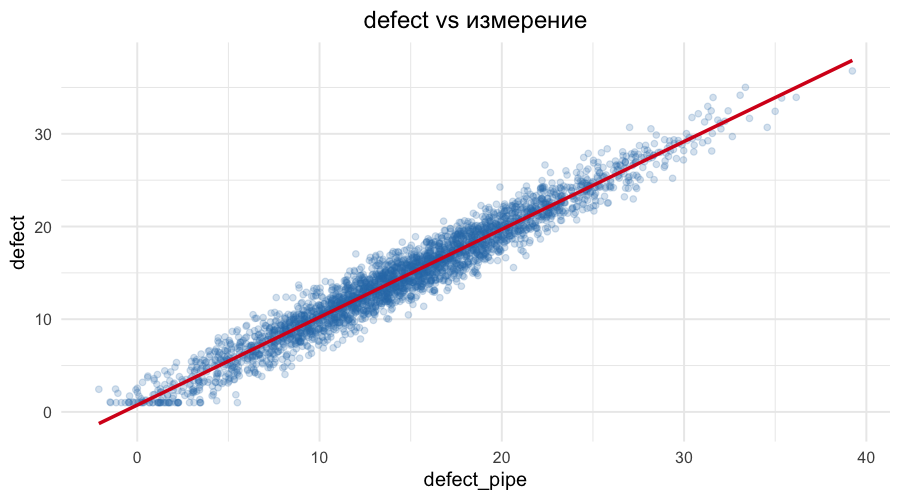

In [8]:
ggplot(scores_norm, aes(defect_pipe, defect)) +
  geom_point(alpha = 0.2, color = "#2c7bb6") +
  geom_smooth(method = "lm", se = FALSE, color = "#d7191c") +
  labs(title = "defect vs измерение", x = "defect_pipe", y = "defect") +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5))


Оценка движется вместе с величиной измерения.

## 3.2. Сводный индекс и все контуры




|               | intercept| coefficient| centered|
|:--------------|---------:|-----------:|--------:|
|output_pipe    |    66.416|       0.308|      100|
|related_pipe   |    90.875|       0.250|      200|
|frequency_pipe |    61.955|       5.068|        1|
|yield_pipe     |    54.623|       0.315|       60|
|volume_pipe    |    62.744|       1.550|        1|
|defect_pipe    |    52.536|      -0.340|       50|


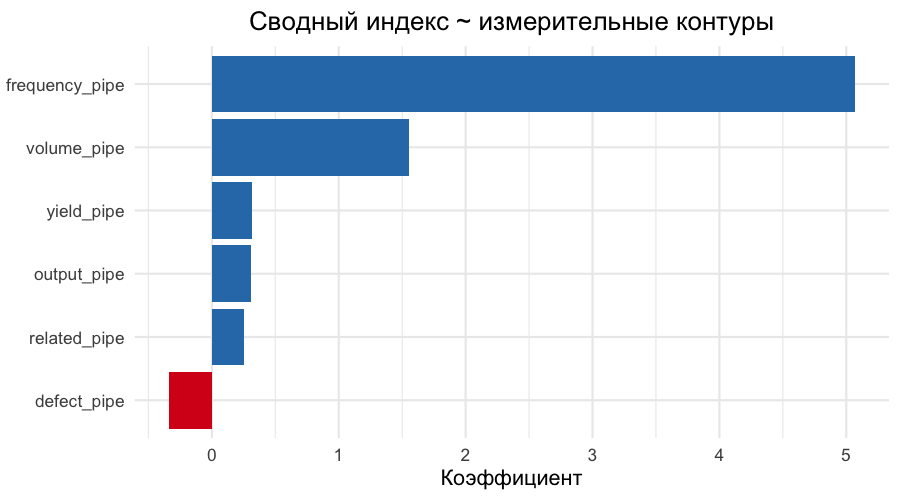

In [9]:
centered <- c(100, 200, 1, 60, 1, 50)
pairs <- expand.grid("overall_index", paste0(estimates, "_pipe"), stringsAsFactors = FALSE)
overall_pipes <- linear_model_one(scores_norm, as.character(pairs$Var1), as.character(pairs$Var2), centered)
knitr::kable(overall_pipes, digits = 3)
print(plot_coefs(overall_pipes, "Сводный индекс ~ измерительные контуры"))


Это ожидаемо: сводный индекс собран из оценок. Отдельно стоит **отрицательное влияние доли брака**: индекс заточен на годную продукцию, а не на брак.

## 3.3. Процессный индекс и контуры




|               | intercept| coefficient| centered|
|:--------------|---------:|-----------:|--------:|
|output_pipe    |    89.304|       0.372|      100|
|related_pipe   |   119.692|       0.310|      200|
|frequency_pipe |    82.856|       8.182|        1|
|yield_pipe     |    75.841|       0.355|       60|


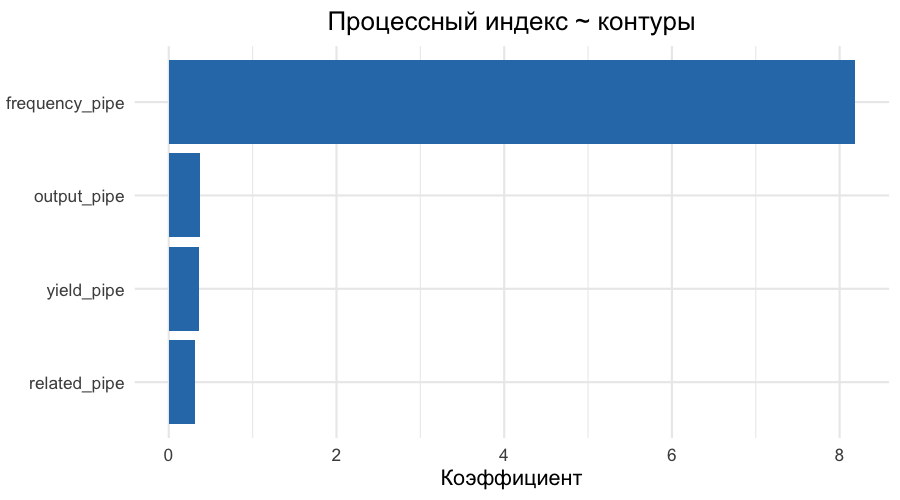

In [10]:
centered <- c(100, 200, 1, 60)
pairs <- expand.grid(
  "process_index",
  paste0(c("output", "related", "frequency", "yield"), "_pipe"),
  stringsAsFactors = FALSE
)
process_pipes <- linear_model_one(scores_norm, as.character(pairs$Var1), as.character(pairs$Var2), centered)
knitr::kable(process_pipes, digits = 3)
print(plot_coefs(process_pipes, "Процессный индекс ~ контуры"))


Процессный индекс тоже следует за своими измерениями.

## 3.4. Продуктовый индекс и контуры




|             | intercept| coefficient| centered|
|:------------|---------:|-----------:|--------:|
|output_pipe  |    63.514|       0.415|      100|
|related_pipe |    99.607|       0.367|      200|
|defect_pipe  |    48.967|      -0.340|       50|


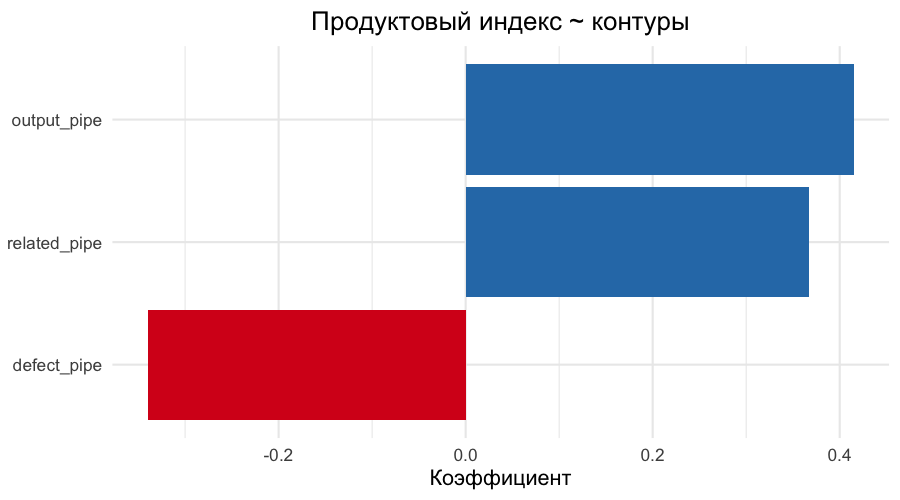

In [11]:
centered <- c(100, 200, 50)
pairs <- expand.grid(
  "product_index",
  paste0(c("output", "related", "defect"), "_pipe"),
  stringsAsFactors = FALSE
)
product_pipes <- linear_model_one(scores_norm, as.character(pairs$Var1), as.character(pairs$Var2), centered)
knitr::kable(product_pipes, digits = 3)
print(plot_coefs(product_pipes, "Продуктовый индекс ~ контуры"))


Снова видно **отрицательное влияние брака**: продуктовый индекс держится на сохранности годной продукции.

Все три индекса смотрят в сторону выпуска и сохранности годной продукции. Брак их снижает.

# 4. Индексы и категории

Какие типы изделий тянут индекс вверх или вниз относительно выбранной базы.

## 4.1. Сводный индекс




Table: type — база: A

|features      | coefficients|
|:-------------|------------:|
|Intercept - A |       64.612|
|B             |       -0.129|


Table: year — база: 2024

|features         | coefficients|
|:----------------|------------:|
|Intercept - 2024 |       65.503|
|2022             |       -0.363|
|2023             |       -0.378|
|2021             |       -0.592|
|2019             |       -0.786|
|2017             |       -1.153|
|2020             |       -1.191|
|2016             |       -1.589|
|2018             |       -1.751|
|2015             |       -2.216|
|2014             |       -2.834|
|2013             |       -3.205|
|2012             |       -3.459|


Table: series — база: Серия_1

|features            | coefficients|
|:-------------------|------------:|
|Intercept - Серия_1 |       62.765|
|Серия_K             |        2.801|
|Серия_J             |        2.580|
|Серия_M             |        2.547|
|Серия_I             |        2.463|
|Серия_L             

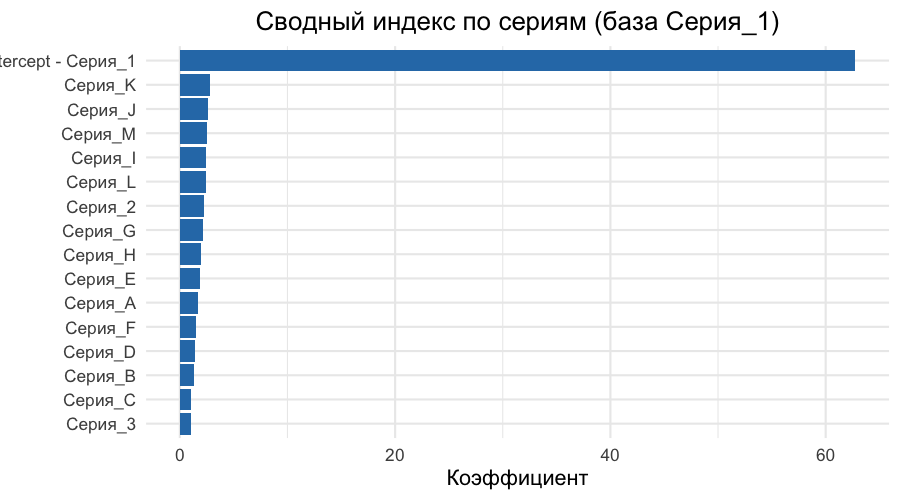

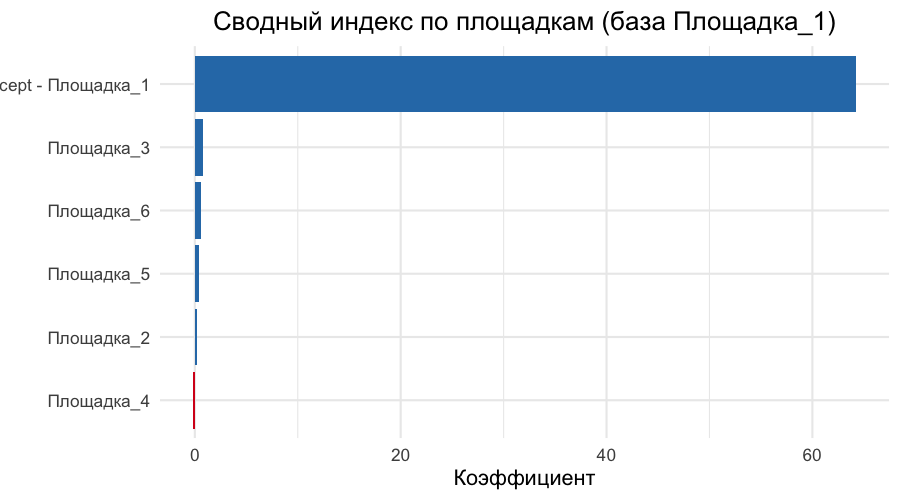

In [12]:
for (i in seq_along(cat_columns)) {
  tab <- linear_model_cat(scores_norm, "overall_index", cat_columns[i], references[i])
  print(knitr::kable(tab, digits = 3, caption = paste(cat_columns[i], "— база:", references[i])))
}
series_tab <- linear_model_cat(scores_norm, "overall_index", "series", "Серия_1")
ggplot(series_tab, aes(x = reorder(features, coefficients), y = coefficients, fill = coefficients > 0)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = c("TRUE" = "#2c7bb6", "FALSE" = "#d7191c"), guide = "none") +
  labs(title = "Сводный индекс по сериям (база Серия_1)", x = NULL, y = "Коэффициент") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))
plant_tab <- linear_model_cat(scores_norm, "overall_index", "plant", "Площадка_1")
ggplot(plant_tab, aes(x = reorder(features, coefficients), y = coefficients, fill = coefficients > 0)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = c("TRUE" = "#2c7bb6", "FALSE" = "#d7191c"), guide = "none") +
  labs(title = "Сводный индекс по площадкам (база Площадка_1)", x = NULL, y = "Коэффициент") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


## 4.2. Процессный индекс


In [13]:
for (i in seq_along(cat_columns)) {
  print(knitr::kable(
    linear_model_cat(scores_norm, "process_index", cat_columns[i], references[i]),
    digits = 3,
    caption = paste(cat_columns[i], "— база:", references[i])
  ))
}




Table: type — база: A

|features      | coefficients|
|:-------------|------------:|
|Intercept - A |       87.110|
|B             |       -0.126|


Table: year — база: 2024

|features         | coefficients|
|:----------------|------------:|
|Intercept - 2024 |       88.017|
|2022             |       -0.102|
|2021             |       -0.416|
|2023             |       -0.421|
|2019             |       -0.891|
|2017             |       -0.968|
|2020             |       -1.227|
|2018             |       -1.559|
|2015             |       -2.235|
|2016             |       -2.358|
|2014             |       -3.145|
|2013             |       -3.356|
|2012             |       -4.584|


Table: series — база: Серия_1

|features            | coefficients|
|:-------------------|------------:|
|Intercept - Серия_1 |       85.534|
|Серия_J             |        2.710|
|Серия_K             |        2.593|
|Серия_L             |        2.303|
|Серия_M             |        2.232|
|Серия_E             

## 4.3. Продуктовый индекс


In [14]:
for (i in seq_along(cat_columns)) {
  print(knitr::kable(
    linear_model_cat(scores_norm, "product_index", cat_columns[i], references[i]),
    digits = 3,
    caption = paste(cat_columns[i], "— база:", references[i])
  ))
}




Table: type — база: A

|features      | coefficients|
|:-------------|------------:|
|Intercept - A |       61.218|
|B             |       -0.481|


Table: year — база: 2024

|features         | coefficients|
|:----------------|------------:|
|Intercept - 2024 |       61.826|
|2021             |       -0.012|
|2023             |       -0.141|
|2022             |       -0.430|
|2019             |       -0.861|
|2020             |       -0.878|
|2017             |       -1.073|
|2016             |       -1.331|
|2018             |       -1.378|
|2015             |       -2.662|
|2014             |       -3.015|
|2012             |       -3.107|
|2013             |       -4.219|


Table: series — база: Серия_1

|features            | coefficients|
|:-------------------|------------:|
|Intercept - Серия_1 |       59.572|
|Серия_L             |        2.786|
|Серия_J             |        2.683|
|Серия_K             |        2.576|
|Серия_M             |        2.451|
|Серия_H             

Динамика по индексам похожая:

- тип A обычно выше типа B;  
- год выпуска 2024 — точка отсчёта;  
- база серии — Серия_1;  
- база площадки — Площадка_1;  
- метод «Ускоренный» чаще выше стандартного;  
- сертификация сама по себе не главный драйвер индекса.

# 5. Несколько переменных сразу

При взаимодействиях растёт риск мультиколлинеарности. Схема такая:

1. Убираем пропуски, центрируем числа по **`r 80`**, категории — по выбранным базам.  
2. `glinternet` ищет взаимодействия.  
3. По найденному набору строится обычная линейная модель.


In [15]:
coef <- 80
reference_levels <- list(series = "Серия_1", plant = "Площадка_1", year = "2024")
threshold <- 10


In [16]:
dataset_mul <- function(dataset, coef) {
  dataset %>%
    select(
      item_id, type, class, year, series, plant, mark, method, certified,
      output, related, frequency, yield, volume, defect,
      overall_index, process_index, product_index
    ) %>%
    drop_na() %>%
    mutate(across(c(output, related, frequency, yield, volume, defect), ~ . - coef)) %>%
    mutate(across(
      all_of(names(reference_levels)),
      ~ factor(., levels = c(reference_levels[[cur_column()]], setdiff(unique(as.character(.)), reference_levels[[cur_column()]])))
    ))
}

glinternet_model <- function(init_data, target, num_variables, cat_variables) {
  dataset <- init_data
  variables <- c(cat_variables, num_variables)
  dataset[cat_variables] <- lapply(dataset[cat_variables], factor)
  num_levels <- sapply(dataset[variables], function(x) if (is.factor(x)) length(levels(x)) else 1)
  X <- as.matrix(data.frame(lapply(dataset[variables], function(x) if (is.factor(x)) as.integer(x) - 1 else x)))
  y <- dataset[[target]]
  stopifnot(length(num_levels) == ncol(X))
  model <- glinternet(X, y, numLevels = num_levels, family = "gaussian")
  active <- model$activeSet[[length(model$activeSet)]]
  main_cat <- cat_variables[active$cat]
  main_cont <- num_variables[active$cont]
  contcont_names <- NULL
  catcont_names <- NULL
  catcat_names <- NULL
  if (!is.null(active$contcont)) {
    contcont_names <- apply(active$contcont, 1, function(pair) paste(num_variables[pair], collapse = "*"))
  }
  if (!is.null(active$catcont)) {
    catcont_names <- apply(active$catcont, 1, function(pair) paste(cat_variables[pair][1], num_variables[pair][2], sep = "*"))
  }
  if (!is.null(active$catcat)) {
    catcat_names <- apply(active$catcat, 1, function(pair) paste(cat_variables[pair], collapse = "*"))
  }
  results <- c(main_cat, main_cont, contcont_names, catcont_names, catcat_names)
  results <- results[!is.na(results) & results != ""]
  if (length(results) == 0) results <- num_variables[1]
  lm(as.formula(paste(target, "~", paste(results, collapse = " + "))), data = init_data)
}

analyse_function <- function(model, threshold) {
  as.data.frame(stats::coef(model)) %>%
    rename_with(~ c("coefficients")) %>%
    mutate(features = rownames(.)) %>%
    `rownames<-`(NULL) %>%
    mutate(n = ifelse(features == "(Intercept)", 1, 0)) %>%
    arrange(desc(n), desc(abs(coefficients))) %>%
    select(features, coefficients) %>%
    filter((grepl(":", features) | features == "(Intercept)") & !grepl("Неизвестно", features)) %>%
    slice_head(n = threshold)
}


## 5.1. Сводный индекс

База: оценки = **`r coef`**, категории = **`r paste(names(reference_levels), reference_levels, sep = " = ", collapse = ", ")`**.


In [17]:
knitr::kable(
  analyse_function(
    glinternet_model(
      dataset_mul(scores_norm, coef),
      "overall_index",
      c("output", "related"),
      c("year", "series", "plant")
    ),
    threshold
  ),
  digits = 4
)




|features                      | coefficients|
|:-----------------------------|------------:|
|(Intercept)                   |      56.8175|
|year2014:seriesСерия_3        |       9.2044|
|year2012:seriesСерия_L        |       8.3614|
|year2015:seriesСерия_3        |       8.3464|
|year2016:seriesСерия_I        |      -8.2137|
|year2014:seriesСерия_F        |       7.0283|
|year2014:plantПлощадка_3      |      -5.4796|
|year2013:seriesСерия_B        |      -5.2946|
|year2019:seriesСерия_I        |      -4.8588|
|seriesСерия_I:plantПлощадка_4 |      -4.8329|


## 5.2. Процессный индекс


In [18]:
knitr::kable(
  analyse_function(
    glinternet_model(
      dataset_mul(scores_norm, coef),
      "process_index",
      c("output", "related"),
      c("year", "series", "plant")
    ),
    threshold
  ),
  digits = 4
)




|features               | coefficients|
|:----------------------|------------:|
|(Intercept)            |      77.5745|
|year2012:seriesСерия_L |     -10.7893|
|year2012:seriesСерия_H |      -8.0541|
|year2016:seriesСерия_I |      -7.7574|
|year2015:seriesСерия_F |      -7.4263|
|year2016:seriesСерия_G |      -7.1777|
|year2012:seriesСерия_3 |      -6.7364|
|year2013:seriesСерия_2 |       6.2149|
|year2012:seriesСерия_G |      -6.2025|
|year2012:seriesСерия_A |      -5.9150|


## 5.3. Продуктовый индекс


In [19]:
knitr::kable(
  analyse_function(
    glinternet_model(
      dataset_mul(scores_norm, coef),
      "product_index",
      c("output", "related"),
      c("year", "series", "plant")
    ),
    threshold
  ),
  digits = 4
)




|features                      | coefficients|
|:-----------------------------|------------:|
|(Intercept)                   |      47.6606|
|year2013:seriesСерия_3        |     -16.1697|
|year2013:seriesСерия_B        |     -15.2290|
|year2013:seriesСерия_K        |     -11.7491|
|year2013:seriesСерия_F        |      -9.5149|
|year2012:seriesСерия_3        |      -8.0309|
|year2013:seriesСерия_G        |      -7.4952|
|seriesСерия_M:plantПлощадка_2 |      -6.3775|
|year2013:plantПлощадка_6      |       6.2189|
|year2013:seriesСерия_A        |      -6.1486|


Главные эффекты оценок сильные, взаимодействия обычно слабые: оценки в значительной степени независимы.

# 6. Заключение

Измерения, оценки и индексы связаны. Брак тянет индексы вниз. Взаимодействия между оценками слабые — лучшее объяснение дают отдельные факторы, а не их произведения.
